# Train and evaluate the MLP on normalized data

## Generate Ligand Embeddings

In [1]:
import torch
from torch.utils import data
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import json
import numpy as np
from transformers import AutoModel, AutoTokenizer
from pathlib import Path

In [2]:
MLP_dir = Path("/Users/isaiahhazelwood/Documents/rotations-2024/fraser-lab/DMS-data/MLP")

with open(MLP_dir / 'ligand.json') as f:
    smiles = json.load(f)

# lig_model_name='DeepChem/ChemBERTa-77M-MLM' # This is a pretrained but not fully initialized model
lig_model_name='seyonec/SMILES_tokenized_PubChem_shard00_160k'
device='cpu'
lig_model = AutoModel.from_pretrained(lig_model_name).to(device)
lig_tokenizer = AutoTokenizer.from_pretrained(lig_model_name)

drug_embeddings = {}
for drug in smiles:
    tokens = lig_tokenizer(smiles[drug], return_tensors="pt", padding=False, truncation=False)
    tokens.to(device)
    with torch.no_grad():
        output = lig_model(**tokens)
    embedding = output.last_hidden_state
    drug_embeddings[drug] = embedding.mean(dim=1).cpu()[0]

In [3]:
torch.save(drug_embeddings, MLP_dir / "ligand_embeddings.pt")

## Create the training and test datasets

In [185]:
# Load mean of full sequence embedding
# prot_embeddings = torch.load(MLP_dir / "muts_embeddings.pt")
# prot_embeddings = {entry['label']: entry['mean_representations'][33] for entry in prot_embeddings}

# Load token of mutated residue
prot_embeddings = torch.load(MLP_dir / "muts_mutated_tok_embeddings.pt")
prot_embeddings = {entry['label']: entry['mutation'][33] for entry in prot_embeddings}
ligand_embeddings = torch.load(MLP_dir / "ligand_embeddings.pt")

score_dir = Path("/Users/isaiahhazelwood/Documents/rotations-2024/fraser-lab/DMS-data/diff-scores")
scores = {}
with open(score_dir / "MET_Estevam_2024_WT.csv") as f_scores:
    for line_no, line in enumerate(f_scores):
        if line_no == 0: # Skip header
            continue
        prot, ligand, wt, pos, mut, score = line.rstrip("\n").split(",")
        ligand = ligand.split("_")[0]
        pos = int(pos)
        score = float(score)
        scores[(prot, ligand, wt, pos, mut)] = score

In [186]:
class LinearDataset(Dataset):
    def __init__(self, scores, prot_embedding_dict, ligand_embedding_dict):
        self.prot_embed = [prot_embedding_dict[f"{prot}_{wt}{pos}{mut}"] for prot, ligand, wt, pos, mut in scores]
        self.lig_embed = [ligand_embedding_dict[ligand] for prot, ligand, wt, pos, mut in scores]
        self.scores = [scores[key] for key in scores]

    def __len__(self):
        return len(self.prot_embed)

    def __getitem__(self, index):
        return self.prot_embed[index], self.lig_embed[index], self.scores[index]

In [208]:
# Fully random train-test splits - easy mode for model
training_indices = np.random.choice(len(scores), size=round(0.7 * len(scores)), replace=False)
training_scores = {}
test_scores = {}
for key_i, key in enumerate(scores):
    if key_i in training_indices:
        training_scores[key] = scores[key]
    else:
        test_scores[key] = scores[key]
training_dataset = LinearDataset(training_scores, prot_embeddings, ligand_embeddings)
test_dataset = LinearDataset(test_scores, prot_embeddings, ligand_embeddings)

In [210]:
# Holdouts in train-test splits
seed = 42
lig_holdout = ["Crizo", "Gle"]
chooser = np.random.default_rng(seed)
positions = list(set(pos for prot, ligand, wt, pos, mut in scores))
pos_holdout = chooser.choice(positions, size=int(len(positions) * 0.2), replace=False)
amino_acids = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']
aa_holdout = chooser.choice(amino_acids, size=2, replace=False)

training_scores = {}
test_scores = {}
for key_i, (prot, ligand, wt, pos, mut) in enumerate(scores):
    if ligand in lig_holdout or pos in pos_holdout or mut in aa_holdout:
        test_scores[(prot, ligand, wt, pos, mut)] = scores[(prot, ligand, wt, pos, mut)]
    else:
        training_scores[(prot, ligand, wt, pos, mut)] = scores[(prot, ligand, wt, pos, mut)]

training_dataset = LinearDataset(training_scores, prot_embeddings, ligand_embeddings)
test_dataset = LinearDataset(test_scores, prot_embeddings, ligand_embeddings)

In [6]:
torch.save(training_dataset, MLP_dir / "random_split/training_dataset.pt")
torch.save(test_dataset, MLP_dir / "random_split/test_dataset.pt")

## Define and Train the Model

In [125]:
from torch import nn
from scipy import stats
from sklearn.model_selection import StratifiedKFold, KFold

In [211]:
params = {
    "n_hidden_channels": 512,
    "n_hidden_layers": 1,
    "n_hidden_inter_channels": 512,
    "n_hidden_inter_layers": 1,
    "lr": 0.0004281903660265339,
    "dropouts": 0.1,
    "decay": 0.000001
}

In [212]:
class MLP(nn.Module):

    def __init__(self, num_prt_embed, num_lig_embed):
        super(MLP,self).__init__()

        # modules_prt = [nn.BatchNorm1d(num_prt_embed)]
        modules_prt = [nn.Linear(num_prt_embed, params['n_hidden_channels'])]
        modules_prt += [nn.ReLU(nn.BatchNorm1d(params['n_hidden_channels']))]
        modules_prt += [nn.Dropout(p=params['dropouts'])]

        for _ in range(params['n_hidden_layers']):
            modules_prt += [nn.Linear(params['n_hidden_channels'], params['n_hidden_channels'])]
            modules_prt += [nn.ReLU(nn.BatchNorm1d(params['n_hidden_channels']))]
            modules_prt += [nn.Dropout(p=params['dropouts'])]
        modules_prt += [nn.Linear(params['n_hidden_channels'], params['n_hidden_channels'])]

        # modules_lig = [nn.BatchNorm1d(num_lig_embed)]
        modules_lig = [nn.Linear(num_lig_embed, params['n_hidden_channels'])]
        modules_lig += [nn.ReLU(nn.BatchNorm1d(params['n_hidden_channels']))]
        modules_lig += [nn.Dropout(p=params['dropouts'])]

        for _ in range(params['n_hidden_layers']):
            modules_lig += [nn.Linear(params['n_hidden_channels'], params['n_hidden_channels'])]
            modules_lig += [nn.ReLU(nn.BatchNorm1d(params['n_hidden_channels']))]
            modules_lig += [nn.Dropout(p=params['dropouts'])]
        modules_lig += [nn.Linear(params['n_hidden_channels'], params['n_hidden_channels'])]

        num_in = int(params['n_hidden_channels']+params['n_hidden_channels'])
        modules = [nn.Linear(num_in, params['n_hidden_inter_channels'])]
        modules += [nn.ReLU(nn.BatchNorm1d(params['n_hidden_inter_channels']))]
        modules += [nn.Dropout(p=params['dropouts'])]
        for _ in range(params['n_hidden_inter_layers']):
            modules += [nn.Linear(params['n_hidden_inter_channels'], params['n_hidden_inter_channels'])]
            modules += [nn.ReLU(nn.BatchNorm1d(params['n_hidden_inter_channels']))]
            modules += [nn.Dropout(p=params['dropouts'])]
        modules += [nn.Linear(params['n_hidden_inter_channels'], 1)]

        self.nn = nn.Sequential(*modules)
        self.prt = nn.Sequential(*modules_prt)
        self.lig = nn.Sequential(*modules_lig)

    def forward(self, prt, lig):
        
        prt = self.prt(prt)
        lig = self.lig(lig)

        x = self.nn(torch.hstack((prt, lig)))

        return x.view(-1)

num_prt_embed = 1280
num_lig_embed = 768

loss_fn = nn.MSELoss()

In [213]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    train_loss = 0.0
    model.train()
    for batch, (prt, lig, y) in enumerate(dataloader):
        prt, lig, y = prt.to(device), lig.to(device), y.float().to(device)
        pred = model(prt, lig)
        loss = loss_fn(pred, y)
        optimizer.zero_grad()
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
    train_loss /= num_batches
    return train_loss

def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss = 0.0
    pred_list = []
    gt_list = []
    
    with torch.no_grad():
        for (prt, lig, y) in dataloader:
            prt, lig, y = prt.to(device), lig.to(device), y.to(device)
            pred = model(prt, lig)
            test_loss += loss_fn(pred, y).item()
            pred_list.append(pred.detach().cpu().numpy().ravel())
            gt_list.append(y.detach().cpu().numpy().ravel())
            
    test_loss /= num_batches
    # print(pred_list)
    slope, intercept, r_value, p_value, std_err = stats.linregress(np.concatenate(gt_list), np.concatenate(pred_list))
    if np.isnan(r_value):
        print("NaN found!")
    return test_loss, np.nan_to_num(r_value)

In [214]:
epochs = 25

batch_size = 128
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# kfold=StratifiedKFold(n_splits=10, shuffle=True)
# labels = [data[-1] for data in training_dataset]
# group_assignment = np.array([round(lb * 20) for lb in labels])
kfold = KFold(n_splits=10, shuffle=True)

cc_list = []
loss_list = []

best_r_spearman = 0.0

num_replicates = 1
for i in (range(num_replicates)):
    print(f"Starting trial {i+1}\n--------------------")
    cc = []
    loss = []
    model = MLP(num_prt_embed, num_lig_embed).float().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=params['lr'], weight_decay=params['decay'])
    # for fold, (train_k_id, valid_k_id) in enumerate(kfold.split(np.zeros(len(training_dataset)), group_assignment)):
    for fold, (train_k_id, valid_k_id) in enumerate(kfold.split(np.zeros(len(training_dataset)))):

        train_subsampler = torch.utils.data.SubsetRandomSampler(train_k_id)
        valid_subsampler = torch.utils.data.SubsetRandomSampler(valid_k_id)

        train_dataloader = DataLoader(training_dataset, batch_size=batch_size, sampler=train_subsampler)
        valid_dataloader = DataLoader(training_dataset, batch_size=batch_size, sampler=valid_subsampler)

        for t in range(epochs):
            if t % int(epochs-1) == 0 and t != 0:
                print(f"Epoch {t+1}\n-------------------------------")
            train_loss = train(train_dataloader, model, loss_fn, optimizer)
            val_loss, r_preason_valid = test(valid_dataloader, model, loss_fn)
            test_loss, r_pearson = test(test_dataloader, model, loss_fn)
        cc.append(np.array([r_preason_valid, r_pearson]))
        loss.append(np.array([train_loss, val_loss, test_loss]))
    cc_list.append(cc)
    loss_list.append(loss)

print("Done!")

Starting trial 1
--------------------
Epoch 25
-------------------------------
Epoch 25
-------------------------------
Epoch 25
-------------------------------
Epoch 25
-------------------------------
Epoch 25
-------------------------------
Epoch 25
-------------------------------
Epoch 25
-------------------------------
Epoch 25
-------------------------------
Epoch 25
-------------------------------
Epoch 25
-------------------------------
Done!


In [215]:
cc_list

[[array([0.90727466, 0.58711555]),
  array([0.93693742, 0.58558218]),
  array([0.96408463, 0.58818533]),
  array([0.97543693, 0.58271187]),
  array([0.98262277, 0.57702622]),
  array([0.98347071, 0.5612048 ]),
  array([0.98904569, 0.56111246]),
  array([0.98867095, 0.55562717]),
  array([0.99137251, 0.54441358]),
  array([0.99109086, 0.55332762])]]

In [216]:
loss_list

[[array([0.06206533, 0.09874594, 0.39149341]),
  array([0.03133135, 0.06897993, 0.3965393 ]),
  array([0.02155645, 0.03845576, 0.4017878 ]),
  array([0.01773647, 0.02877386, 0.42146511]),
  array([0.01540737, 0.01863088, 0.42262678]),
  array([0.0142639 , 0.02069443, 0.41971787]),
  array([0.01354932, 0.01472763, 0.41873926]),
  array([0.01237985, 0.01305714, 0.43510522]),
  array([0.01189166, 0.00979436, 0.44964504]),
  array([0.00986868, 0.01015323, 0.45248613])]]

In [245]:
test_ligand_holdout_scores = {}
test_aa_holdout_scores = {}
test_pos_holdout_scores = {}
for key_i, (prot, ligand, wt, pos, mut) in enumerate(scores):
    # Each mutation in the test set appears only once across all buckets
    # Here I theorize the ligand information is most important, then mut, then pos
    if ligand in lig_holdout:
        test_ligand_holdout_scores[(prot, ligand, wt, pos, mut)] = scores[(prot, ligand, wt, pos, mut)]
    elif mut in aa_holdout:
        test_aa_holdout_scores[(prot, ligand, wt, pos, mut)] = scores[(prot, ligand, wt, pos, mut)]
    elif pos in pos_holdout:
        test_pos_holdout_scores[(prot, ligand, wt, pos, mut)] = scores[(prot, ligand, wt, pos, mut)]

test_ligand_holdout_dataset = LinearDataset(test_ligand_holdout_scores, prot_embeddings, ligand_embeddings)
test_ligand_holdout_dataloader = DataLoader(test_ligand_holdout_dataset, batch_size=batch_size, shuffle=False)

test_aa_holdout_dataset = LinearDataset(test_aa_holdout_scores, prot_embeddings, ligand_embeddings)
test_aa_holdout_dataloader = DataLoader(test_aa_holdout_dataset, batch_size=batch_size, shuffle=False)

test_pos_holdout_dataset = LinearDataset(test_pos_holdout_scores, prot_embeddings, ligand_embeddings)
test_pos_holdout_dataloader = DataLoader(test_pos_holdout_dataset, batch_size=batch_size, shuffle=False)


test_ligand_holdout_preds = []
test_aa_holdout_preds = []
test_pos_holdout_preds = []
gt_ligand_holdout = []
gt_aa_holdout = []
gt_pos_holdout = []
with torch.no_grad():
    for (prt, lig, y) in test_ligand_holdout_dataloader:
        prt, lig, y = prt.to(device), lig.to(device), y.to(device)
        pred = model(prt, lig)
        test_ligand_holdout_preds.append(pred.detach().cpu().numpy().ravel())
        gt_ligand_holdout.append(y.detach().cpu().numpy().ravel())
    for (prt, lig, y) in test_aa_holdout_dataloader:
        prt, lig, y = prt.to(device), lig.to(device), y.to(device)
        pred = model(prt, lig)
        test_aa_holdout_preds.append(pred.detach().cpu().numpy().ravel())
        gt_aa_holdout.append(y.detach().cpu().numpy().ravel())
    for (prt, lig, y) in test_pos_holdout_dataloader:
        prt, lig, y = prt.to(device), lig.to(device), y.to(device)
        pred = model(prt, lig)
        test_pos_holdout_preds.append(pred.detach().cpu().numpy().ravel())
        gt_pos_holdout.append(y.detach().cpu().numpy().ravel())

test_ligand_holdout_preds = np.concatenate(test_ligand_holdout_preds)
test_aa_holdout_preds = np.concatenate(test_aa_holdout_preds)
test_pos_holdout_preds = np.concatenate(test_pos_holdout_preds)

gt_ligand_holdout = np.concatenate(gt_ligand_holdout)
gt_aa_holdout = np.concatenate(gt_aa_holdout)
gt_pos_holdout = np.concatenate(gt_pos_holdout)

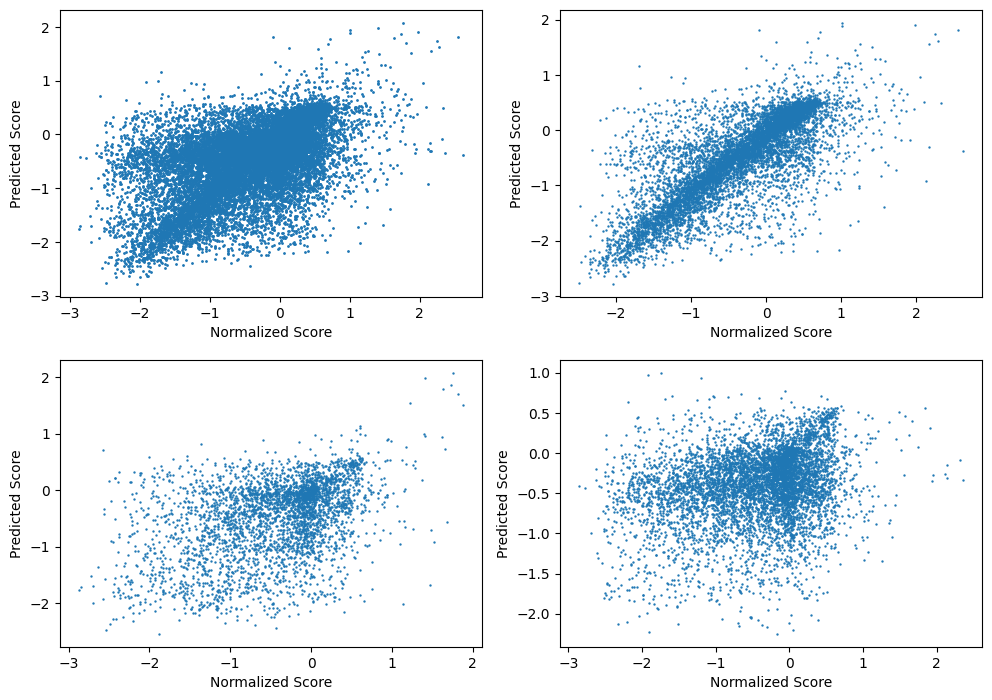

In [261]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2)
axs[0, 0].scatter(np.concatenate((gt_ligand_holdout, gt_aa_holdout, gt_pos_holdout)), 
                  np.concatenate((test_ligand_holdout_preds, test_aa_holdout_preds, test_pos_holdout_preds)), 
                  s=1)
axs[0, 1].scatter(gt_ligand_holdout, test_ligand_holdout_preds, s=0.5)
axs[1, 0].scatter(gt_aa_holdout, test_aa_holdout_preds, s=0.5)
axs[1, 1].scatter(gt_pos_holdout, test_pos_holdout_preds, s=0.5)
for i in range(4):
    axs[i // 2, i % 2].set_xlabel("Normalized Score", size=10)
    axs[i // 2, i % 2].set_ylabel("Predicted Score", size=10)

fig.tight_layout(pad=0)
fig.set_figwidth(10)
fig.set_figheight(7)
plt.show()

In [252]:
slope, intercept, r_value, p_value, std_err = stats.linregress(np.concatenate((gt_ligand_holdout, gt_aa_holdout, gt_pos_holdout)), 
                                                               np.concatenate((test_ligand_holdout_preds, test_aa_holdout_preds, test_pos_holdout_preds)))
print(f"Whole test set: {r_value}")
slope, intercept, r_value, p_value, std_err = stats.linregress(gt_ligand_holdout, test_ligand_holdout_preds)
print(f"Ligand holdout set: {r_value}")
slope, intercept, r_value, p_value, std_err = stats.linregress(gt_aa_holdout, test_aa_holdout_preds)
print(f"AA holdout set: {r_value}")
slope, intercept, r_value, p_value, std_err = stats.linregress(gt_pos_holdout, test_pos_holdout_preds)
print(f"Pos holdout set: {r_value}")


Whole test set: 0.5533276181151547
Ligand holdout set: 0.7652833361457905
AA holdout set: 0.41780451826940207
Pos holdout set: 0.2639206045074247
